# James Robinson
# DSC 680 Project 1

## Start-Up

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [52]:
from pathlib import Path
import matplotlib.pyplot as plt

# Create a folder for exported charts
output_folder = Path("figures")
output_folder.mkdir(exist_ok=True)

# Function to save the current chart
def save_chart(filename):
    fig = plt.gcf()

    fig.savefig(
        output_folder / filename,
        dpi=300,
        bbox_inches='tight',
        facecolor='white',
        format='png'
    )

    print(f"Saved: {output_folder / filename}")

## Data Import

In [2]:
data = pd.read_csv("Data/us_average_prices_monthly.csv") 
print("Rows:", data.shape[0])
print("Columns:", data.shape[1])

data.head()

Rows: 8869
Columns: 8


,date,year,month,item,unit,category,price,series_id
0,2015-01-01,2015,1,All Ham (Excluding Canned Ham and Luncheon Sli...,lb. (453.6 gm),"Meat, broad category",3.211,APU0000FD2101
1,2015-02-01,2015,2,All Ham (Excluding Canned Ham and Luncheon Sli...,lb. (453.6 gm),"Meat, broad category",3.221,APU0000FD2101
2,2015-03-01,2015,3,All Ham (Excluding Canned Ham and Luncheon Sli...,lb. (453.6 gm),"Meat, broad category",3.176,APU0000FD2101
3,2015-04-01,2015,4,All Ham (Excluding Canned Ham and Luncheon Sli...,lb. (453.6 gm),"Meat, broad category",2.971,APU0000FD2101
4,2015-05-01,2015,5,All Ham (Excluding Canned Ham and Luncheon Sli...,lb. (453.6 gm),"Meat, broad category",3.045,APU0000FD2101


In [3]:
data_summ = pd.read_csv("Data/us_average_prices_item_summary.csv")
print("Rows:", data_summ.shape[0])
print("Columns:", data_summ.shape[1])

data_summ.head()

Rows: 74
Columns: 14


,item,unit,category,first_date,last_date,first_price,last_price,n_months,min_price,max_price,avg_first_12mo,avg_last_12mo,pct_change_12mo_avg,is_current
0,"Coffee, 100%, ground roast, all sizes",lb. (453.6 gm),Beef,2015-01-01,2026-07-01,4.738,9.317,123,4.053,9.723,4.720,9.265,96.29,True
1,"Orange juice, frozen concentrate, 12 oz. can",16 oz. (473.2 ml),Fruit,2015-01-01,2026-07-01,2.732,4.817,138,2.257,4.970,2.710,4.822,77.93,True
2,Utility (piped) gas,therm,Energy,2015-01-01,2026-07-01,1.036,1.704,138,0.877,1.819,0.945,1.676,77.35,True
3,"Lettuce, romaine",lb. (453.6 gm),Vegetables,2015-01-01,2026-07-01,2.047,3.469,115,1.790,4.021,1.986,3.389,70.64,True
4,All Uncooked Other Beef (Excluding Veal),lb. (453.6 gm),"Meat, broad category",2015-01-01,2026-07-01,4.734,8.009,137,4.406,8.222,4.661,7.924,70.01,True


## Quick Insights

### Main Dataset

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8869 entries, 0 to 8868
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date       8869 non-null   object 
 1   year       8869 non-null   int64  
 2   month      8869 non-null   int64  
 3   item       8869 non-null   object 
 4   unit       8869 non-null   object 
 5   category   8869 non-null   object 
 6   price      8869 non-null   float64
 7   series_id  8869 non-null   object 
dtypes: float64(1), int64(2), object(5)
memory usage: 554.4+ KB


In [5]:
data.isnull().sum()

date         0
year         0
month        0
item         0
unit         0
category     0
price        0
series_id    0
dtype: int64

In [6]:
data['category'].value_counts()

category
Beef                    1595
Energy                  1107
Pork and deli            960
Vegetables               916
Dairy and fats           906
Fruit                    859
Bakery and grains        824
Poultry                  475
Drinks                   474
Meat, broad category     407
Pantry and snacks        208
Eggs                     138
Name: count, dtype: int64

### Second Dataset

In [7]:
data_summ.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74 entries, 0 to 73
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   item                 74 non-null     object 
 1   unit                 74 non-null     object 
 2   category             74 non-null     object 
 3   first_date           74 non-null     object 
 4   last_date            74 non-null     object 
 5   first_price          74 non-null     float64
 6   last_price           74 non-null     float64
 7   n_months             74 non-null     int64  
 8   min_price            74 non-null     float64
 9   max_price            74 non-null     float64
 10  avg_first_12mo       74 non-null     float64
 11  avg_last_12mo        74 non-null     float64
 12  pct_change_12mo_avg  60 non-null     float64
 13  is_current           74 non-null     bool   
dtypes: bool(1), float64(7), int64(1), object(5)
memory usage: 7.7+ KB


In [8]:
data_summ.isnull().sum()

item                    0
unit                    0
category                0
first_date              0
last_date               0
first_price             0
last_price              0
n_months                0
min_price               0
max_price               0
avg_first_12mo          0
avg_last_12mo           0
pct_change_12mo_avg    14
is_current              0
dtype: int64

## Data Cleaning

In [9]:
data['date'] = pd.to_datetime(data['date'])
data_summ['first_date'] = pd.to_datetime(data_summ['first_date'])
data_summ['last_date'] = pd.to_datetime(data_summ['last_date'])


In [10]:
data = data.drop(columns=['series_id'])

## Data Extraction for Relevance

In [11]:
data.groupby(['category', 'item'])['price'].count()

category           item                             
Bakery and grains  Bread, white, pan                    138
                   Bread, whole wheat, pan              136
                   Cookies, chocolate chip              138
                   Flour, white, all purpose            137
                   Rice, white, long grain, uncooked    137
                                                       ... 
Vegetables         Lettuce, romaine                     115
                   Peppers, sweet                        58
                   Potato chips                         138
                   Potatoes, white                      135
                   Tomatoes, field grown                136
Name: price, Length: 74, dtype: int64

In [12]:
data[['category', 'item', 'unit']].drop_duplicates().sort_values(
    ['category', 'item'])


,category,item,unit
2027,Bakery and grains,"Bread, white, pan",lb. (453.6 gm)
2165,Bakery and grains,"Bread, whole wheat, pan",lb. (453.6 gm)
3585,Bakery and grains,"Cookies, chocolate chip",lb. (453.6 gm)
4036,Bakery and grains,"Flour, white, all purpose",lb. (453.6 gm)
7198,Bakery and grains,"Rice, white, long grain, uncooked",lb. (453.6 gm)
...,...,...,...
6025,Vegetables,"Lettuce, romaine",lb. (453.6 gm)
6867,Vegetables,"Peppers, sweet",lb. (453.6 gm)
6925,Vegetables,Potato chips,16 oz.
7063,Vegetables,"Potatoes, white",lb. (453.6 gm)


In [13]:
gas = data[data['item'].isin(['Automotive diesel fuel', 'Gasoline, unleaded regular','Gasoline, unleaded midgrade','Gasoline, unleaded premium'])].copy()

gas.head()

,date,year,month,item,unit,category,price
1293,2015-01-01,2015,1,Automotive diesel fuel,gallon/3.785 liters,Energy,2.964
1294,2015-02-01,2015,2,Automotive diesel fuel,gallon/3.785 liters,Energy,2.875
1295,2015-03-01,2015,3,Automotive diesel fuel,gallon/3.785 liters,Energy,2.933
1296,2015-04-01,2015,4,Automotive diesel fuel,gallon/3.785 liters,Energy,2.840
1297,2015-05-01,2015,5,Automotive diesel fuel,gallon/3.785 liters,Energy,2.906


In [14]:
gas.groupby(['year', 'item'])['price'].mean()


year  item                       
2015  Automotive diesel fuel         2.744917
      Gasoline, unleaded midgrade    2.688667
      Gasoline, unleaded premium     2.865833
      Gasoline, unleaded regular     2.447750
2016  Automotive diesel fuel         2.291583
      Gasoline, unleaded midgrade    2.400583
      Gasoline, unleaded premium     2.610083
      Gasoline, unleaded regular     2.141750
2017  Automotive diesel fuel         2.625750
      Gasoline, unleaded midgrade    2.692333
      Gasoline, unleaded premium     2.911417
      Gasoline, unleaded regular     2.407500
2018  Automotive diesel fuel         3.158333
      Gasoline, unleaded midgrade    3.030833
      Gasoline, unleaded premium     3.269583
      Gasoline, unleaded regular     2.735333
2019  Automotive diesel fuel         3.074250
      Gasoline, unleaded midgrade    2.963500
      Gasoline, unleaded premium     3.211583
      Gasoline, unleaded regular     2.636250
2020  Automotive diesel fuel         2.621750


In [15]:
grocery = data[~data['category'].isin(['Pantry and snacks', 'Energy','Fruit','Drinks'])].copy()
grocery.head()

,date,year,month,item,unit,category,price
0,2015-01-01,2015,1,All Ham (Excluding Canned Ham and Luncheon Sli...,lb. (453.6 gm),"Meat, broad category",3.211
1,2015-02-01,2015,2,All Ham (Excluding Canned Ham and Luncheon Sli...,lb. (453.6 gm),"Meat, broad category",3.221
2,2015-03-01,2015,3,All Ham (Excluding Canned Ham and Luncheon Sli...,lb. (453.6 gm),"Meat, broad category",3.176
3,2015-04-01,2015,4,All Ham (Excluding Canned Ham and Luncheon Sli...,lb. (453.6 gm),"Meat, broad category",2.971
4,2015-05-01,2015,5,All Ham (Excluding Canned Ham and Luncheon Sli...,lb. (453.6 gm),"Meat, broad category",3.045


In [16]:
data_summ.sort_values('pct_change_12mo_avg', ascending=False)

,item,unit,category,first_date,last_date,first_price,last_price,n_months,min_price,max_price,avg_first_12mo,avg_last_12mo,pct_change_12mo_avg,is_current
0,"Coffee, 100%, ground roast, all sizes",lb. (453.6 gm),Beef,2015-01-01,2026-07-01,4.738,9.317,123,4.053,9.723,4.720,9.265,96.29,True
1,"Orange juice, frozen concentrate, 12 oz. can",16 oz. (473.2 ml),Fruit,2015-01-01,2026-07-01,2.732,4.817,138,2.257,4.970,2.710,4.822,77.93,True
2,Utility (piped) gas,therm,Energy,2015-01-01,2026-07-01,1.036,1.704,138,0.877,1.819,0.945,1.676,77.35,True
3,"Lettuce, romaine",lb. (453.6 gm),Vegetables,2015-01-01,2026-07-01,2.047,3.469,115,1.790,4.021,1.986,3.389,70.64,True
4,All Uncooked Other Beef (Excluding Veal),lb. (453.6 gm),"Meat, broad category",2015-01-01,2026-07-01,4.734,8.009,137,4.406,8.222,4.661,7.924,70.01,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69,"Pears, Anjou",lb. (453.6 gm),Fruit,2016-06-01,2019-07-01,1.650,1.552,31,1.513,1.726,1.632,1.596,NaN,False
70,"Peppers, sweet",lb. (453.6 gm),Vegetables,2015-01-01,2020-03-01,2.427,2.437,58,2.043,2.888,2.496,2.392,NaN,False
71,"Steak, round, graded and ungraded, excluding U...",lb. (453.6 gm),Beef,2015-01-01,2026-04-01,6.161,9.328,67,5.304,9.335,6.087,8.704,NaN,False
72,"Sugar, white, 33-80 oz. pkg",lb. (453.6 gm),Pantry and snacks,2015-01-01,2022-10-01,0.626,0.793,70,0.549,0.793,0.646,0.700,NaN,False


In [17]:
data_summ.sort_values(
    'pct_change_12mo_avg',
    ascending=False
)[['item', 'category', 'pct_change_12mo_avg']]

,item,category,pct_change_12mo_avg
0,"Coffee, 100%, ground roast, all sizes",Beef,96.29
1,"Orange juice, frozen concentrate, 12 oz. can",Fruit,77.93
2,Utility (piped) gas,Energy,77.35
3,"Lettuce, romaine",Vegetables,70.64
4,All Uncooked Other Beef (Excluding Veal),"Meat, broad category",70.01
...,...,...,...
69,"Pears, Anjou",Fruit,NaN
70,"Peppers, sweet",Vegetables,NaN
71,"Steak, round, graded and ungraded, excluding U...",Beef,NaN
72,"Sugar, white, 33-80 oz. pkg",Pantry and snacks,NaN


In [18]:
groc_summ = data_summ[~data_summ['category'].isin(['Pantry and snacks', 'Energy','Fruit','Drinks'])].copy()
groc_summ.head()

,item,unit,category,first_date,last_date,first_price,last_price,n_months,min_price,max_price,avg_first_12mo,avg_last_12mo,pct_change_12mo_avg,is_current
0,"Coffee, 100%, ground roast, all sizes",lb. (453.6 gm),Beef,2015-01-01,2026-07-01,4.738,9.317,123,4.053,9.723,4.720,9.265,96.29,True
3,"Lettuce, romaine",lb. (453.6 gm),Vegetables,2015-01-01,2026-07-01,2.047,3.469,115,1.790,4.021,1.986,3.389,70.64,True
4,All Uncooked Other Beef (Excluding Veal),lb. (453.6 gm),"Meat, broad category",2015-01-01,2026-07-01,4.734,8.009,137,4.406,8.222,4.661,7.924,70.01,True
6,"Steak, sirloin, USDA Choice, boneless",lb. (453.6 gm),Beef,2015-01-01,2026-07-01,8.080,14.592,138,7.790,14.727,8.570,14.131,64.89,True
8,"Chuck roast, USDA Choice, boneless",lb. (453.6 gm),Beef,2015-01-01,2026-07-01,5.624,9.631,138,4.792,9.631,5.603,9.133,63.00,True


In [19]:
gas_summ = data_summ[data_summ['item'].isin(['Automotive diesel fuel', 'Gasoline, unleaded regular','Gasoline, unleaded midgrade','Gasoline, unleaded premium'])].copy()

gas_summ.head()

,item,unit,category,first_date,last_date,first_price,last_price,n_months,min_price,max_price,avg_first_12mo,avg_last_12mo,pct_change_12mo_avg,is_current
10,Automotive diesel fuel,gallon/3.785 liters,Energy,2015-01-01,2026-07-01,2.964,5.077,138,2.040,5.780,2.745,4.420,61.02,True
12,"Gasoline, unleaded premium",gallon/3.785 liters,Energy,2015-01-01,2026-07-01,2.497,5.027,139,2.248,5.774,2.866,4.514,57.50,True
22,"Gasoline, unleaded midgrade",gallon/3.785 liters,Energy,2015-01-01,2026-07-01,2.340,4.583,139,2.029,5.369,2.689,4.077,51.62,True
27,"Gasoline, unleaded regular",gallon/3.785 liters,Energy,2015-01-01,2026-07-01,2.110,4.094,139,1.767,5.058,2.448,3.602,47.14,True


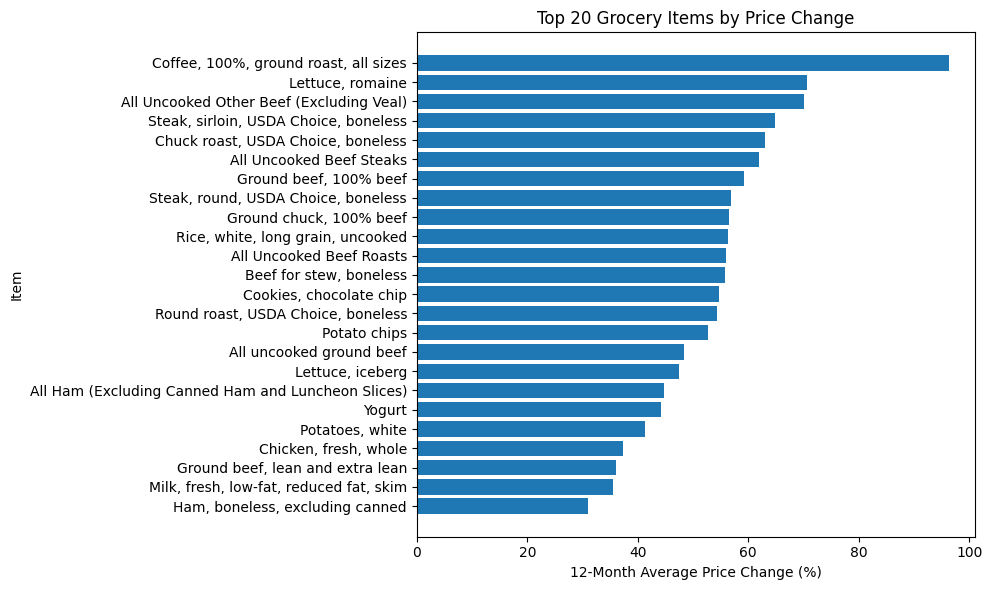

In [20]:
plot_data = groc_summ.nlargest(24, 'pct_change_12mo_avg')

plt.figure(figsize=(10, 6))

plt.barh(plot_data['item'], plot_data['pct_change_12mo_avg'])

plt.xlabel('12-Month Average Price Change (%)')
plt.ylabel('Item')
plt.title('Top 20 Grocery Items by Price Change')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

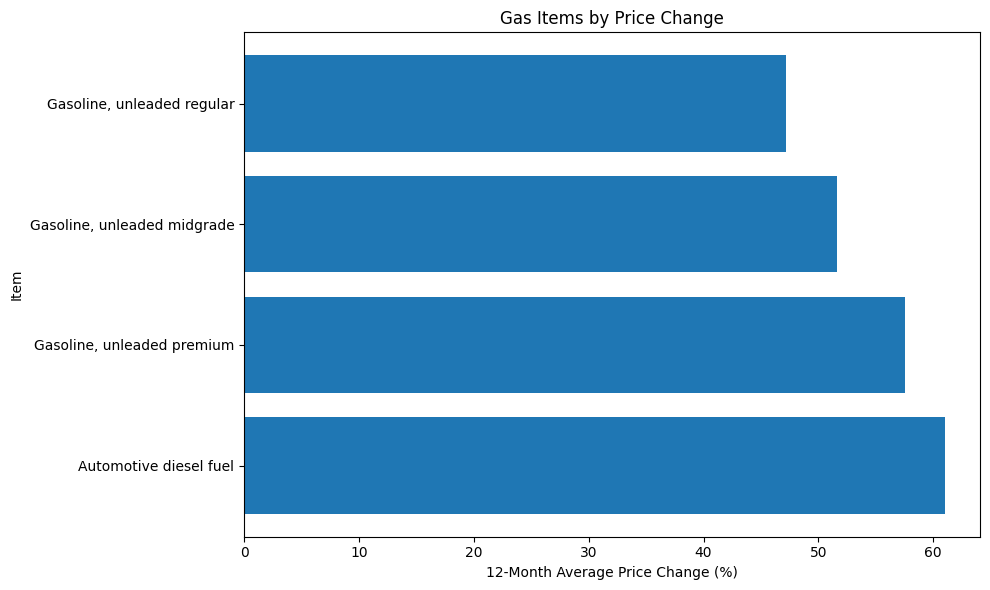

In [21]:
plt.figure(figsize=(10, 6))

plt.barh(gas_summ['item'], gas_summ['pct_change_12mo_avg'])

plt.xlabel('12-Month Average Price Change (%)')
plt.ylabel('Item')
plt.title('Gas Items by Price Change')

plt.tight_layout()
plt.show()

Saved: figures\01_groc_price.png


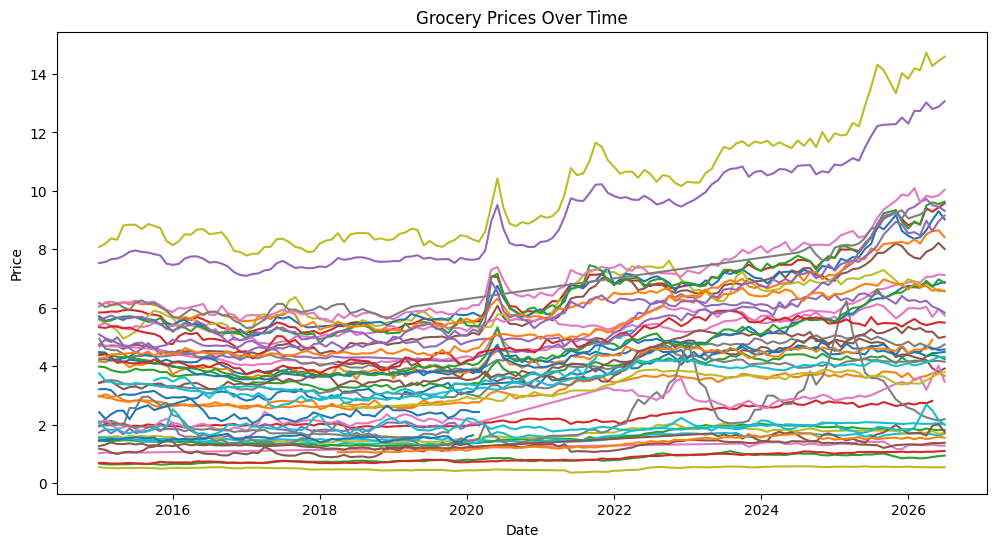

In [58]:
plt.figure(figsize=(12, 6))

for item in grocery['item'].unique():
    groc_item = grocery[grocery['item'] == item]
    
    plt.plot(
        groc_item['date'],
        groc_item['price'],
        label=item
    )

plt.xlabel('Date')
plt.ylabel('Price')
plt.title('Grocery Prices Over Time')
#plt.legend()
#plt.tight_layout()
save_chart('01_groc_price.png')
plt.show()

Saved: figures\01_gas_price.png


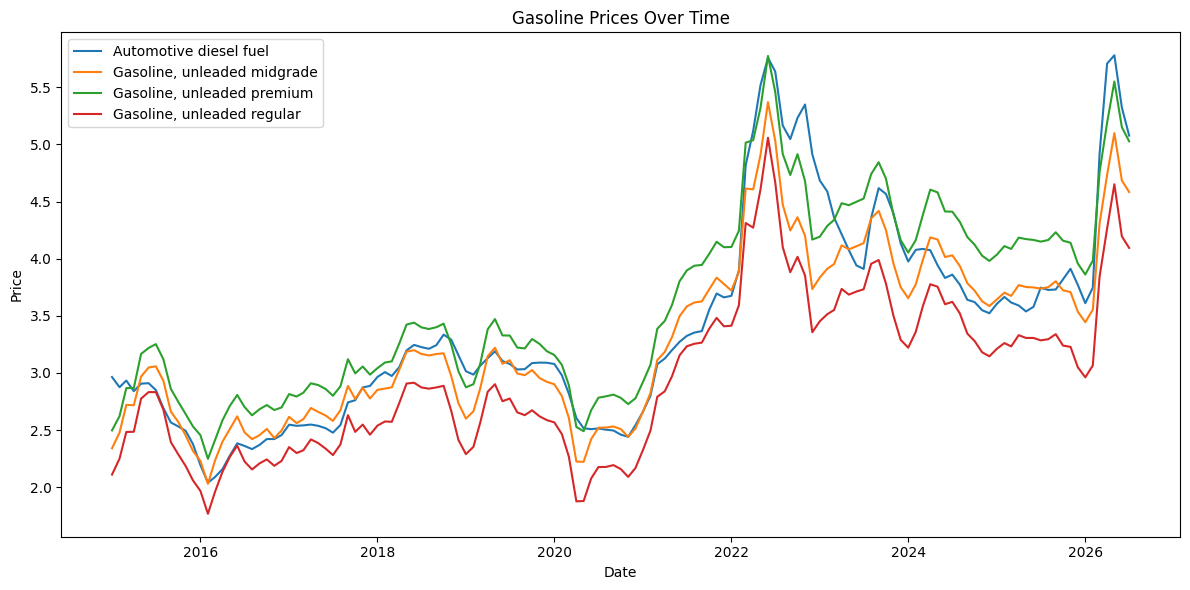

In [59]:
plt.figure(figsize=(12, 6))

for item in gas['item'].unique():
    gas_item = gas[gas['item'] == item]
    
    plt.plot(
        gas_item['date'],
        gas_item['price'],
        label=item
    )

plt.xlabel('Date')
plt.ylabel('Price')
plt.title('Gasoline Prices Over Time')
plt.legend()
plt.tight_layout()
save_chart('01_gas_price.png')
plt.show()

In [23]:
gas_summ = data_summ[
    data_summ['category'] == 'Energy'
].copy()

gas_summ[[
    'item',
    'avg_first_12mo',
    'avg_last_12mo',
    'pct_change_12mo_avg'
]].sort_values(
    'pct_change_12mo_avg',
    ascending=False
)

,item,avg_first_12mo,avg_last_12mo,pct_change_12mo_avg
2,Utility (piped) gas,0.945,1.676,77.35
7,Fuel oil #2,2.601,4.241,63.05
10,Automotive diesel fuel,2.745,4.420,61.02
12,"Gasoline, unleaded premium",2.866,4.514,57.50
22,"Gasoline, unleaded midgrade",2.689,4.077,51.62
23,"Gasoline, all types",2.510,3.750,49.40
27,"Gasoline, unleaded regular",2.448,3.602,47.14
33,Electricity,0.138,0.192,39.13


In [37]:
JR_items = ['All uncooked ground beef', 'American processed cheese', 'Bread, white, pan','Bread, whole wheat, pan',
            'Chicken breast, boneless','Flour, white, all purpose','Frankfurters, all meat or all beef',
            'Peppers, sweet','Potato chips','Potatoes, white','Tomatoes, field grown', 'Automotive diesel fuel', 'Gasoline, unleaded regular']

JR_data = data[data['item'].isin(JR_items)].copy()
JR_summ = data_summ[data_summ['item'].isin(JR_items)].copy()



In [38]:
JR_data.head()

,date,year,month,item,unit,category,price
1018,2015-01-01,2015,1,All uncooked ground beef,lb. (453.6 gm),Beef,4.675
1019,2015-02-01,2015,2,All uncooked ground beef,lb. (453.6 gm),Beef,4.708
1020,2015-03-01,2015,3,All uncooked ground beef,lb. (453.6 gm),Beef,4.677
1021,2015-04-01,2015,4,All uncooked ground beef,lb. (453.6 gm),Beef,4.681
1022,2015-05-01,2015,5,All uncooked ground beef,lb. (453.6 gm),Beef,4.653


In [39]:
JR_summ.head()

,item,unit,category,first_date,last_date,first_price,last_price,n_months,min_price,max_price,avg_first_12mo,avg_last_12mo,pct_change_12mo_avg,is_current
10,Automotive diesel fuel,gallon/3.785 liters,Energy,2015-01-01,2026-07-01,2.964,5.077,138,2.040,5.780,2.745,4.420,61.02,True
21,Potato chips,16 oz.,Vegetables,2015-01-01,2026-07-01,4.263,6.559,138,4.263,6.971,4.408,6.735,52.79,True
24,All uncooked ground beef,lb. (453.6 gm),Beef,2015-01-01,2026-07-01,4.675,7.116,138,4.029,7.141,4.628,6.865,48.34,True
27,"Gasoline, unleaded regular",gallon/3.785 liters,Energy,2015-01-01,2026-07-01,2.110,4.094,139,1.767,5.058,2.448,3.602,47.14,True
31,"Potatoes, white",lb. (453.6 gm),Vegetables,2015-01-01,2026-07-01,0.668,0.942,135,0.633,1.094,0.650,0.919,41.38,True


In [40]:
data_wide = pd.read_csv("Data/us_average_prices_wide.csv")
data_wide['date'] = pd.to_datetime(data_wide['date'])
print("Rows:", data_wide.shape[0])
print("Columns:", data_wide.shape[1])

Rows: 139
Columns: 75


In [41]:
JR_wide = data_wide[JR_items].copy()

JR_wide.corr()

,All uncooked ground beef,American processed cheese,"Bread, white, pan","Bread, whole wheat, pan","Chicken breast, boneless","Flour, white, all purpose","Frankfurters, all meat or all beef","Peppers, sweet",Potato chips,"Potatoes, white","Tomatoes, field grown",Automotive diesel fuel,"Gasoline, unleaded regular"
All uncooked ground beef,1.000000,0.720901,0.842199,0.903497,0.823804,0.523040,0.908302,0.330784,0.912940,0.731946,0.152754,0.685699,0.685213
American processed cheese,0.720901,1.000000,0.842172,0.835785,0.782448,0.880153,-0.118610,-0.049073,0.784246,0.650294,0.107520,0.430062,0.424785
"Bread, white, pan",0.842199,0.842172,1.000000,0.945701,0.903068,0.638255,0.868783,0.162476,0.959006,0.882160,0.126733,0.686396,0.700336
"Bread, whole wheat, pan",0.903497,0.835785,0.945701,1.000000,0.832692,0.649526,0.596194,-0.271190,0.963851,0.859937,0.152589,0.626263,0.634809
"Chicken breast, boneless",0.823804,0.782448,0.903068,0.832692,1.000000,0.605591,0.848969,0.032505,0.902276,0.814885,0.090444,0.821299,0.809393
"Flour, white, all purpose",0.523040,0.880153,0.638255,0.649526,0.605591,1.000000,-0.481892,-0.214368,0.582171,0.483399,0.073207,0.290135,0.274870
"Frankfurters, all meat or all beef",0.908302,-0.118610,0.868783,0.596194,0.848969,-0.481892,1.000000,0.459130,0.870525,0.390178,-0.060914,0.553581,0.568803
"Peppers, sweet",0.330784,-0.049073,0.162476,-0.271190,0.032505,-0.214368,0.459130,1.000000,0.349454,-0.147492,0.135971,0.080740,0.020062
Potato chips,0.912940,0.784246,0.959006,0.963851,0.902276,0.582171,0.870525,0.349454,1.000000,0.909130,0.135268,0.737901,0.737417
"Potatoes, white",0.731946,0.650294,0.882160,0.859937,0.814885,0.483399,0.390178,-0.147492,0.909130,1.000000,0.087717,0.719055,0.729651


Saved: figures\01_heat1.png


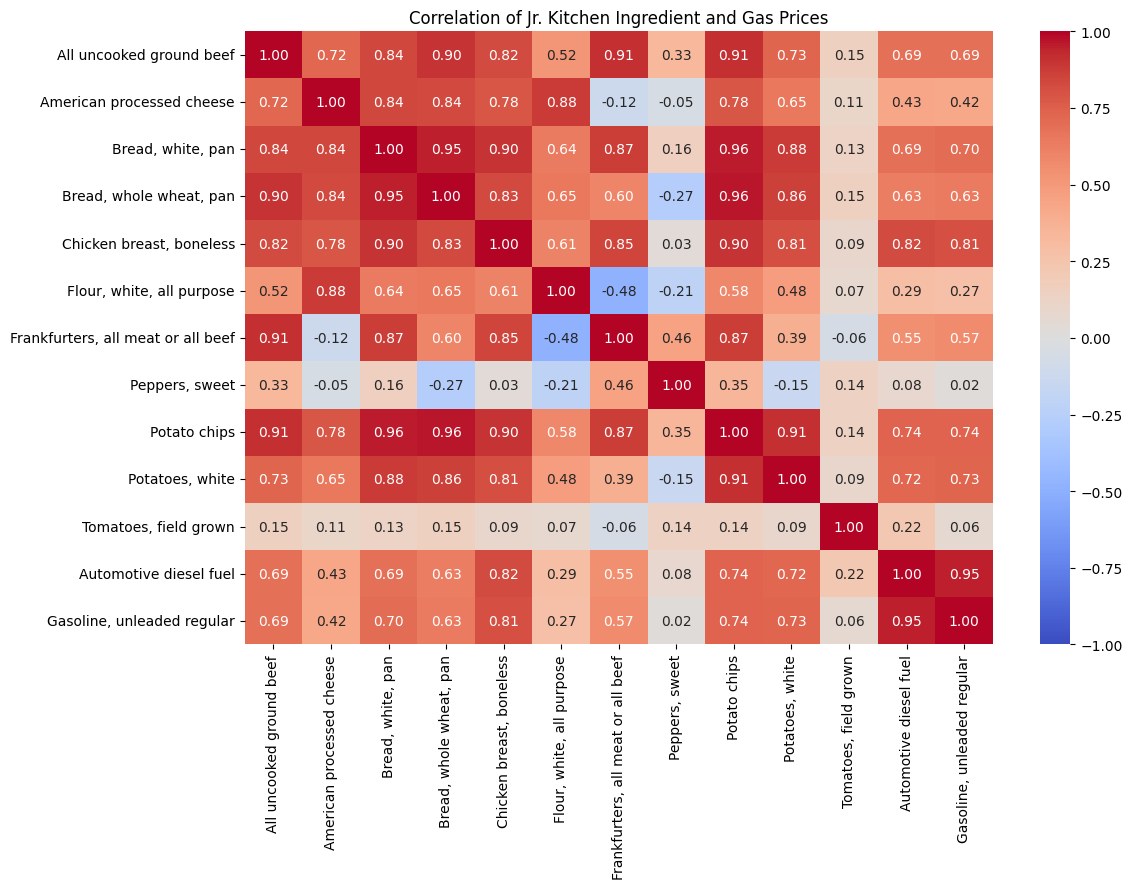

In [60]:
JR_corr = JR_wide.corr()

plt.figure(figsize=(12, 9))

sns.heatmap(JR_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0, fmt='.2f')

plt.title('Correlation of Jr. Kitchen Ingredient and Gas Prices')
plt.tight_layout()
save_chart('01_heat1.png')

plt.show()

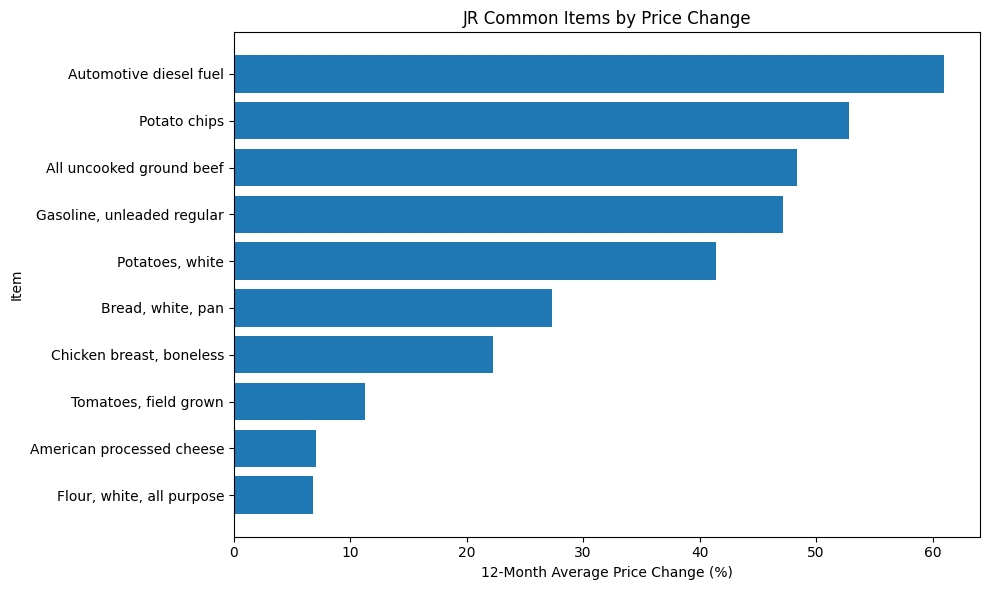

In [43]:
plt.figure(figsize=(10, 6))

plt.barh(JR_summ['item'], JR_summ['pct_change_12mo_avg'])

plt.xlabel('12-Month Average Price Change (%)')
plt.ylabel('Item')
plt.title('JR Common Items by Price Change')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Saved: figures\01_groc_lineprice.png


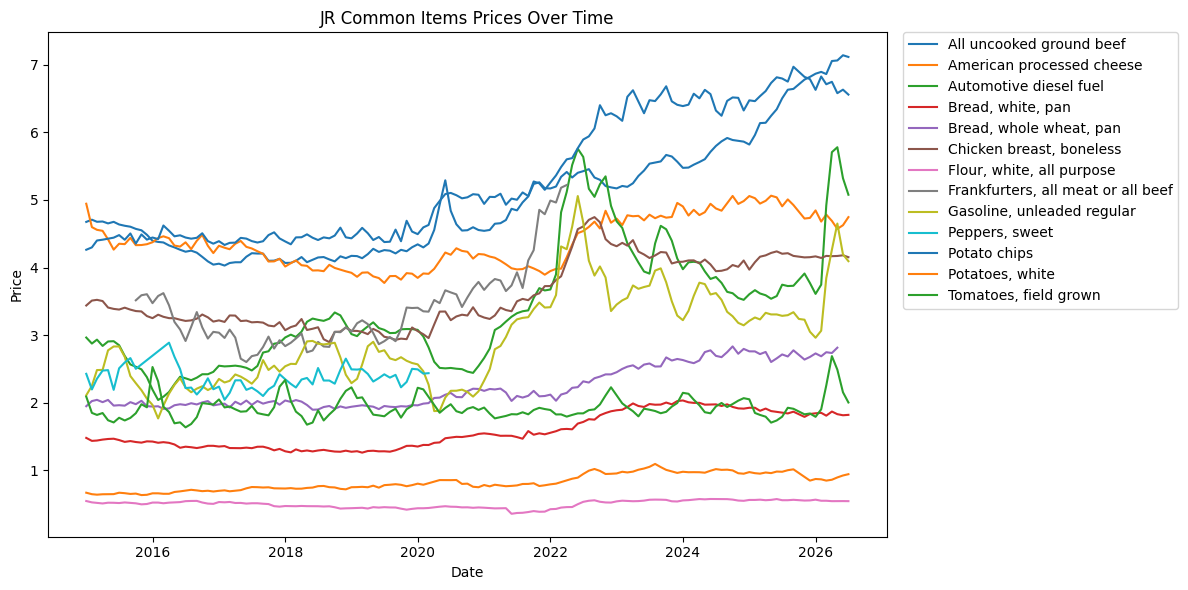

In [63]:
plt.figure(figsize=(12, 6))

for item in JR_data['item'].unique():
    JR_item = JR_data[JR_data['item'] == item]

    plt.plot(
        JR_item['date'],
        JR_item['price'],
        label=item
    )

plt.xlabel('Date')
plt.ylabel('Price')
plt.title('JR Common Items Prices Over Time')

# Move legend outside the plot (right side)
plt.legend(
    loc='upper left',
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0
)

plt.tight_layout()
save_chart('01_groc_lineprice.png')
plt.show()

In [45]:
# Create a focused dataset with date and selected items
JR_compare = data_wide[['date'] + JR_items].copy()

JR_compare = JR_compare.sort_values('date').set_index('date')

# Calculate year-over-year percentage changes
JR_yoy = JR_compare.pct_change(
    periods=12,
    fill_method=None
) * 100

# Display the most recent 12 months
JR_yoy.tail(12)

,All uncooked ground beef,American processed cheese,"Bread, white, pan","Bread, whole wheat, pan","Chicken breast, boneless","Flour, white, all purpose","Frankfurters, all meat or all beef","Peppers, sweet",Potato chips,"Potatoes, white","Tomatoes, field grown",Automotive diesel fuel,"Gasoline, unleaded regular"
date,,,,,,,,,,,,,
2025-08-01,13.021987,3.449700,-5.638134,0.373972,6.578947,-2.961672,NaN,NaN,8.085175,-0.497018,-3.557114,-1.245693,-6.418631
2025-09-01,12.269731,-0.525146,-5.516194,0.982533,4.982386,-1.745201,NaN,NaN,7.810084,0.495540,-1.342975,2.472527,-0.149522
2025-10-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1.219884
2025-11-01,15.440926,-4.371585,-6.576200,-3.157122,3.465470,0.000000,NaN,NaN,4.761173,NaN,-9.950739,10.200056,1.477523
2025-12-01,16.339758,-4.996990,-4.131799,-4.256080,1.193957,1.094891,NaN,NaN,7.337128,-10.748156,-10.982100,7.069847,-3.020668
2026-01-01,18.006873,-4.211151,-4.259740,-1.123188,4.938272,0.713012,NaN,NaN,2.394192,-10.483042,-12.634146,0.138696,-7.785737
2026-02-01,15.668512,-6.884202,-3.896104,-2.609641,1.544496,-2.139037,NaN,NaN,5.648406,-9.508882,2.922078,2.210095,-6.010426
2026-03-01,11.829884,-3.295592,-3.829787,1.029790,0.288462,-2.831858,NaN,NaN,2.692778,-10.842105,23.969214,36.034292,18.904703
2026-04-01,14.881146,-5.955484,-2.300052,-0.581607,-0.287081,-2.513465,NaN,NaN,2.072304,-11.065150,49.972114,58.969359,28.018018


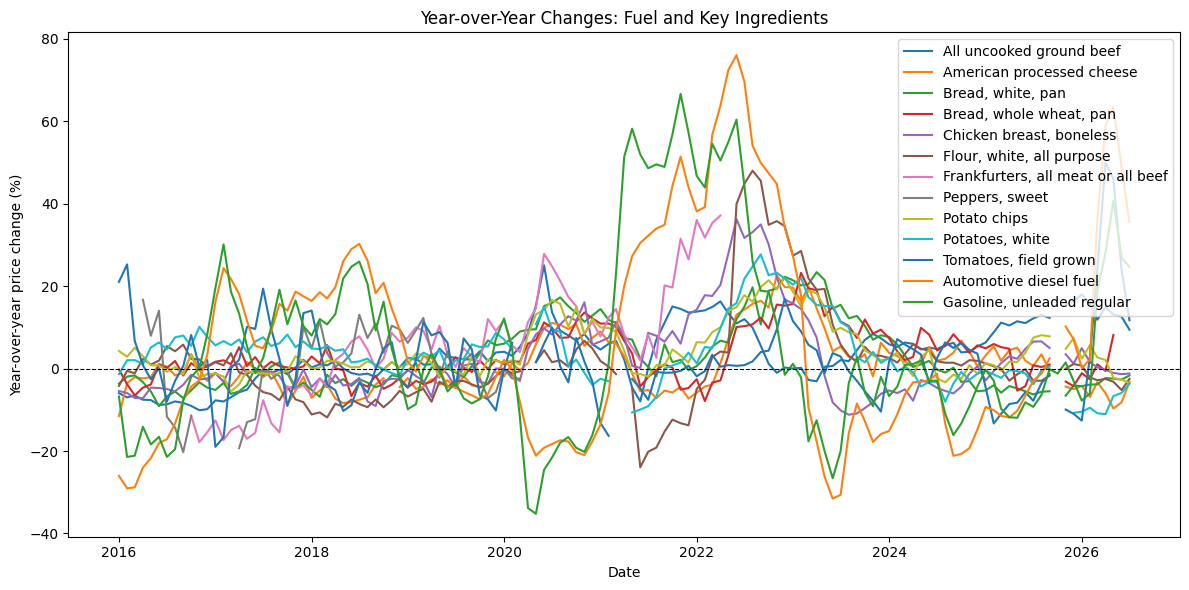

In [46]:
compare_items = [
    'Gasoline, unleaded regular',
    'Automotive diesel fuel',
    'All uncooked ground beef',
    'Frankfurters, all meat or all beef'
]

plt.figure(figsize=(12, 6))

for item in JR_wide:
    plt.plot(
        JR_yoy.index,
        JR_yoy[item],
        label=item
    )

plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.xlabel('Date')
plt.ylabel('Year-over-year price change (%)')
plt.title('Year-over-Year Changes: Fuel and Key Ingredients')
plt.legend()
plt.tight_layout()
plt.show()

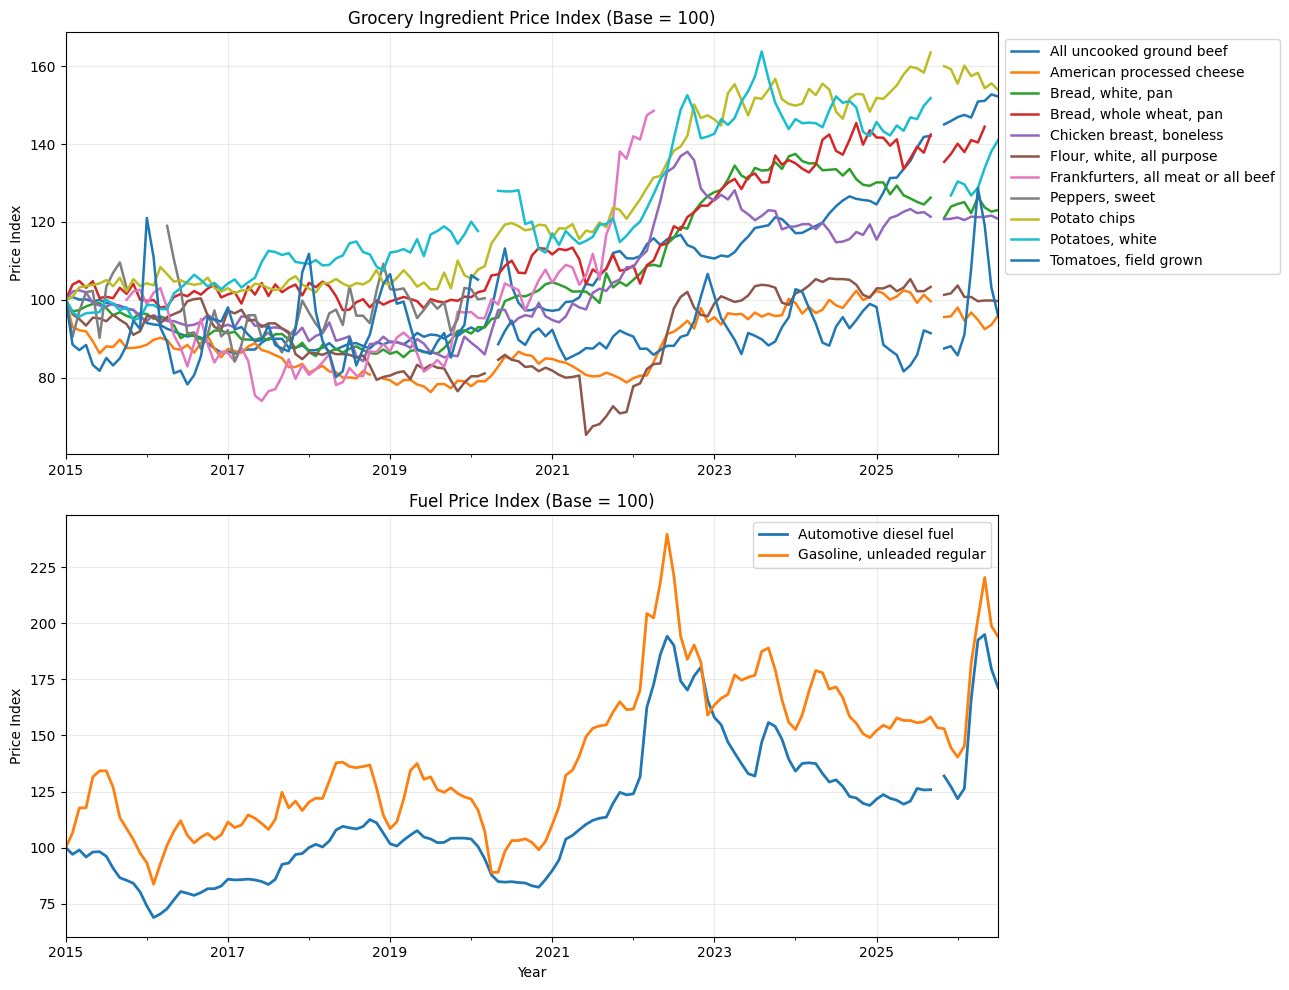

In [47]:
# Create a price index (first available month = 100)
JR_index = JR_compare.div(JR_compare.bfill().iloc[0]).mul(100)

# Separate groceries from fuel
grocery_items = [item for item in JR_items
                 if item not in ['Automotive diesel fuel',
                                 'Gasoline, unleaded regular']]

fig, axes = plt.subplots(2, 1, figsize=(13, 10))

JR_index[grocery_items].plot(ax=axes[0], linewidth=1.8)

axes[0].set_title('Grocery Ingredient Price Index (Base = 100)')
axes[0].set_ylabel('Price Index')
axes[0].set_xlabel('')
axes[0].grid(alpha=0.25)
axes[0].legend(loc='upper left', bbox_to_anchor=(1, 1))

JR_index[['Automotive diesel fuel',
          'Gasoline, unleaded regular']].plot(
    ax=axes[1], linewidth=2
)

axes[1].set_title('Fuel Price Index (Base = 100)')
axes[1].set_ylabel('Price Index')
axes[1].set_xlabel('Year')
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

Saved: figures\01_yoy_heat.png


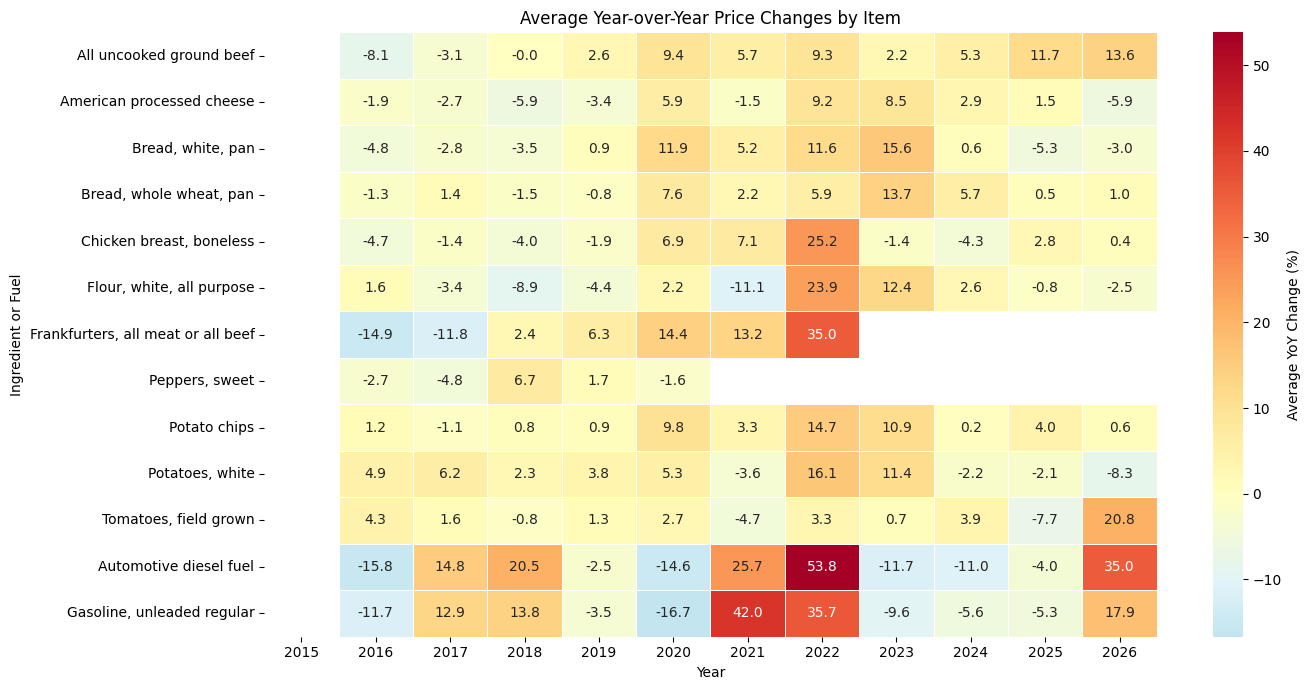

In [64]:
# Average year-over-year changes by calendar year
JR_yoy_year = JR_yoy.copy()
JR_yoy_year['year'] = JR_yoy_year.index.year

annual_changes = JR_yoy_year.groupby('year').mean()

plt.figure(figsize=(14, 7))

sns.heatmap(
    annual_changes.T,
    annot=True,
    fmt='.1f',
    cmap='RdYlBu_r',
    center=0,
    linewidths=0.5,
    cbar_kws={'label': 'Average YoY Change (%)'}
)

plt.title('Average Year-over-Year Price Changes by Item')
plt.xlabel('Year')
plt.ylabel('Ingredient or Fuel')
plt.tight_layout()
save_chart('01_yoy_heat.png')
plt.show()

Saved: figures\01_yoy.png


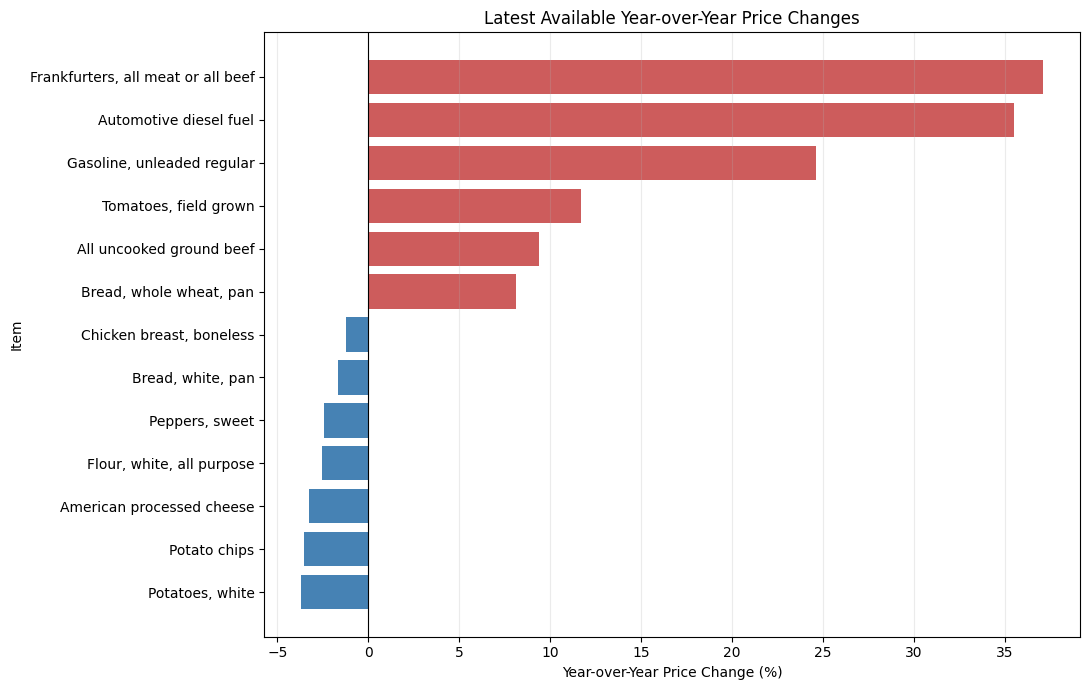

In [65]:
# Get the latest available YoY change for each item
latest_changes = JR_yoy.apply(
    lambda col: col.dropna().iloc[-1]
    if col.notna().any() else np.nan
).dropna().sort_values()

plt.figure(figsize=(11, 7))

colors = ['steelblue' if x < 0 else 'indianred'
          for x in latest_changes]

plt.barh(
    latest_changes.index,
    latest_changes.values,
    color=colors
)

plt.axvline(0, color='black', linewidth=0.8)

plt.xlabel('Year-over-Year Price Change (%)')
plt.ylabel('Item')
plt.title('Latest Available Year-over-Year Price Changes')

plt.grid(axis='x', alpha=0.25)
plt.tight_layout()
save_chart('01_yoy.png')
plt.show()

Saved: figures\01_heat2.png


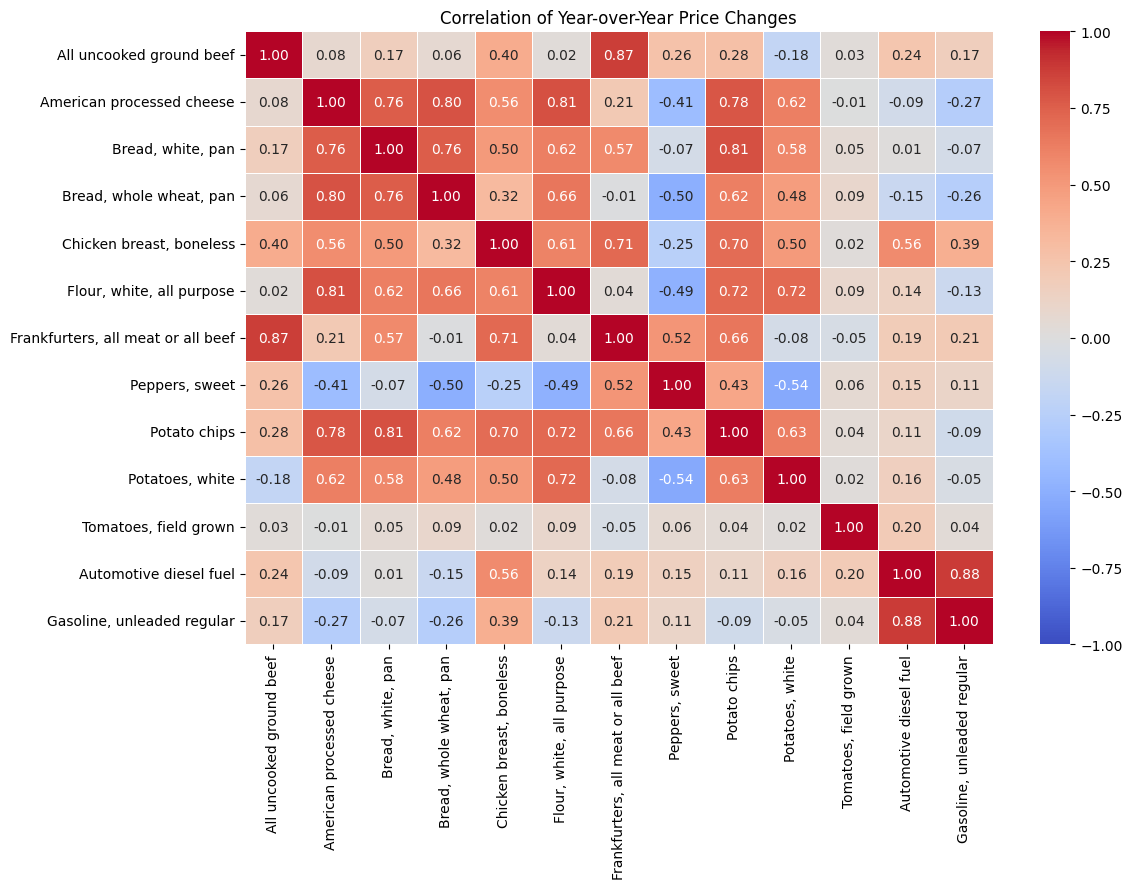

In [66]:
# Correlation between year-over-year price changes
JR_yoy_corr = JR_yoy.corr(min_periods=24)

plt.figure(figsize=(12, 9))

sns.heatmap(
    JR_yoy_corr,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation of Year-over-Year Price Changes')
plt.tight_layout()
save_chart('01_heat2.png')

plt.show()